# Shared multitask model: load, evaluate, and plot

This notebook reuses the configuration, dataset setup, and model-definition cells from `shared_multitask_dinov3_dpt_poc.ipynb`, but does not train. It loads the saved checkpoint, evaluates it, and creates qualitative plots.

Set `CHECKPOINT` below to the checkpoint you want to inspect.

In [13]:
from pathlib import Path
import json
import numpy as np
import torch
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()
TRAIN_NOTEBOOK = PROJECT_DIR / "lusnar.ipynb"
# Existing run was saved under ~/lusnar_runs; future runs use PROJECT_DIR/runs/.
CHECKPOINT = PROJECT_DIR / "run" / "dpt_shared_multitask_poc" / "shared_multitask_best.pt"
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("project:", PROJECT_DIR)
print("checkpoint:", CHECKPOINT)
print("checkpoint exists:", CHECKPOINT.exists())

project: /gorilla/proj/uppmax2026-1-299/taiko_sandbox_please_work
checkpoint: /gorilla/proj/uppmax2026-1-299/taiko_sandbox_please_work/run/dpt_shared_multitask_poc/shared_multitask_best.pt
checkpoint exists: True


In [14]:
# Reuse the original notebook's setup/model cells without executing its training cell.
import contextlib, math, re, time
import numpy as np
import pandas as pd
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
nb = json.loads(TRAIN_NOTEBOOK.read_text())
def cell_source_containing(text):
    for cell in nb["cells"]:
        src = "".join(cell.get("source", []))
        if cell.get("cell_type") == "code" and text in src:
            return src
    raise KeyError(text)

exec(cell_source_containing('ROOT = Path('), globals())
NUM_WORKERS = min(NUM_WORKERS, 2)
exec(cell_source_containing('# Same dataset setup'), globals())
exec(cell_source_containing('class SharedDPT'), globals())
if "model" not in globals():
    model = SharedDPT(DEPTH_MIN, DEPTH_MAX).to(DEVICE)
print("model loaded on:", next(model.parameters()).device)

CODE_DIR: /proj/uppmax2026-1-299/task1_groupc_dataset 
ROOT: /proj/uppmax2026-1-299/task1_groupc_dataset/lusnar/extracted 
DINO_WEIGHTS: /proj/uppmax2026-1-299/task1_groupc_dataset/dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth 
device: cuda
train:  8,338 frames | scenes ['Moon_1', 'Moon_2', 'Moon_4', 'Moon_5', 'Moon_6', 'Moon_7']
val  :  1,351 frames | scenes ['Moon_8']
test :  3,317 frames | scenes ['Moon_3', 'Moon_9']
{'train': 8338, 'val': 1351, 'test': 3317}
depth bins: 1.0523437500000001 1681.2 classes: ['Lunar Regolith', 'Impact Crater', 'Rock', 'Mountain', 'Sky']
Loaded local pretrained weights
model loaded on: cuda:0


In [15]:
if not CHECKPOINT.exists():
    raise FileNotFoundError(f"Checkpoint not found: {CHECKPOINT}")
ck = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=False)
missing, unexpected = model.load_state_dict(ck["model"], strict=False)
print("checkpoint epoch:", ck.get("epoch"))
print("checkpoint metrics:", ck.get("metrics"))
print("missing keys:", len(missing), "unexpected keys:", len(unexpected))
model.eval()

checkpoint epoch: 4
checkpoint metrics: {'mIoU': 0.8836105525021363, 'AbsRel': 0.40893828767392476, 'RMSE': 20.32006424961048}
missing keys: 0 unexpected keys: 0


SharedDPT(
  (backbone): DinoFeatures(
    (model): DINOv3ViTModel(
      (embeddings): DINOv3ViTEmbeddings(
        (patch_embeddings): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (rope_embeddings): DINOv3ViTRopePositionEmbedding()
      (model): DINOv3ViTEncoder(
        (layer): ModuleList(
          (0-11): 12 x DINOv3ViTLayer(
            (norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
            (attention): DINOv3ViTAttention(
              (k_proj): Linear(in_features=768, out_features=768, bias=False)
              (v_proj): Linear(in_features=768, out_features=768, bias=True)
              (q_proj): Linear(in_features=768, out_features=768, bias=True)
              (o_proj): Linear(in_features=768, out_features=768, bias=True)
            )
            (layer_scale1): DINOv3ViTLayerScale()
            (drop_path): Identity()
            (norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
            (mlp): DINOv3ViTMLP(
     

In [16]:
@torch.no_grad()
def evaluate_results(m, loader, max_batches=None):
    m.eval(); conf=torch.zeros(L.NUM_CLASSES,L.NUM_CLASSES,dtype=torch.long,device=DEVICE); absrel=[]; rmse=[]
    for i,b in enumerate(loader):
        if max_batches is not None and i >= max_batches: break
        b={k:v.to(DEVICE) if torch.is_tensor(v) else v for k,v in b.items()}
        with autocast(): o=m(b["image"])
        pred=o["seg"].argmax(1); mask=b["label"]!=L.IGNORE_INDEX
        conf += torch.bincount(b["label"][mask]*L.NUM_CLASSES+pred[mask],minlength=L.NUM_CLASSES**2).view(L.NUM_CLASSES,L.NUM_CLASSES)
        for j in range(pred.shape[0]):
            v=b["depth_valid"][j,0]
            if v.sum()>10:
                p,g=o["depth"][j,0][v].clamp_min(1e-3),b["depth"][j,0][v]
                absrel.append(float(((p-g).abs()/g).mean())); rmse.append(float(((p-g)**2).mean().sqrt()))
    tp=conf.diag().double(); iou=tp/(conf.sum(0)+conf.sum(1)-tp)
    return {"mIoU":float(torch.nanmean(iou)),"AbsRel":float(np.mean(absrel)),"RMSE":float(np.mean(rmse)),"IoU":{n:float(v) for n,v in zip(L.CLASS_NAMES,iou)}}

results={"val":evaluate_results(model,val_loader)}
if test_loader is not None: results["test"]=evaluate_results(model,test_loader)
print(json.dumps(results,indent=2))
(RESULTS_DIR/"metrics.json").write_text(json.dumps(results,indent=2))

{
  "val": {
    "mIoU": 0.8835858102649701,
    "AbsRel": 0.4093554447219603,
    "RMSE": 20.282005555006773,
    "IoU": {
      "Lunar Regolith": 0.9867055511649457,
      "Impact Crater": 0.8279859217916868,
      "Rock": 0.7218157274325395,
      "Mountain": 0.8886206066954879,
      "Sky": 0.9928012442401902
    }
  },
  "test": {
    "mIoU": 0.8356108498093423,
    "AbsRel": 0.3298872752400957,
    "RMSE": 45.18600048471151,
    "IoU": {
      "Lunar Regolith": 0.9777402785114513,
      "Impact Crater": 0.5875117754455086,
      "Rock": 0.7554393879414414,
      "Mountain": 0.8652448183697101,
      "Sky": 0.9921179887785998
    }
  }
}


650

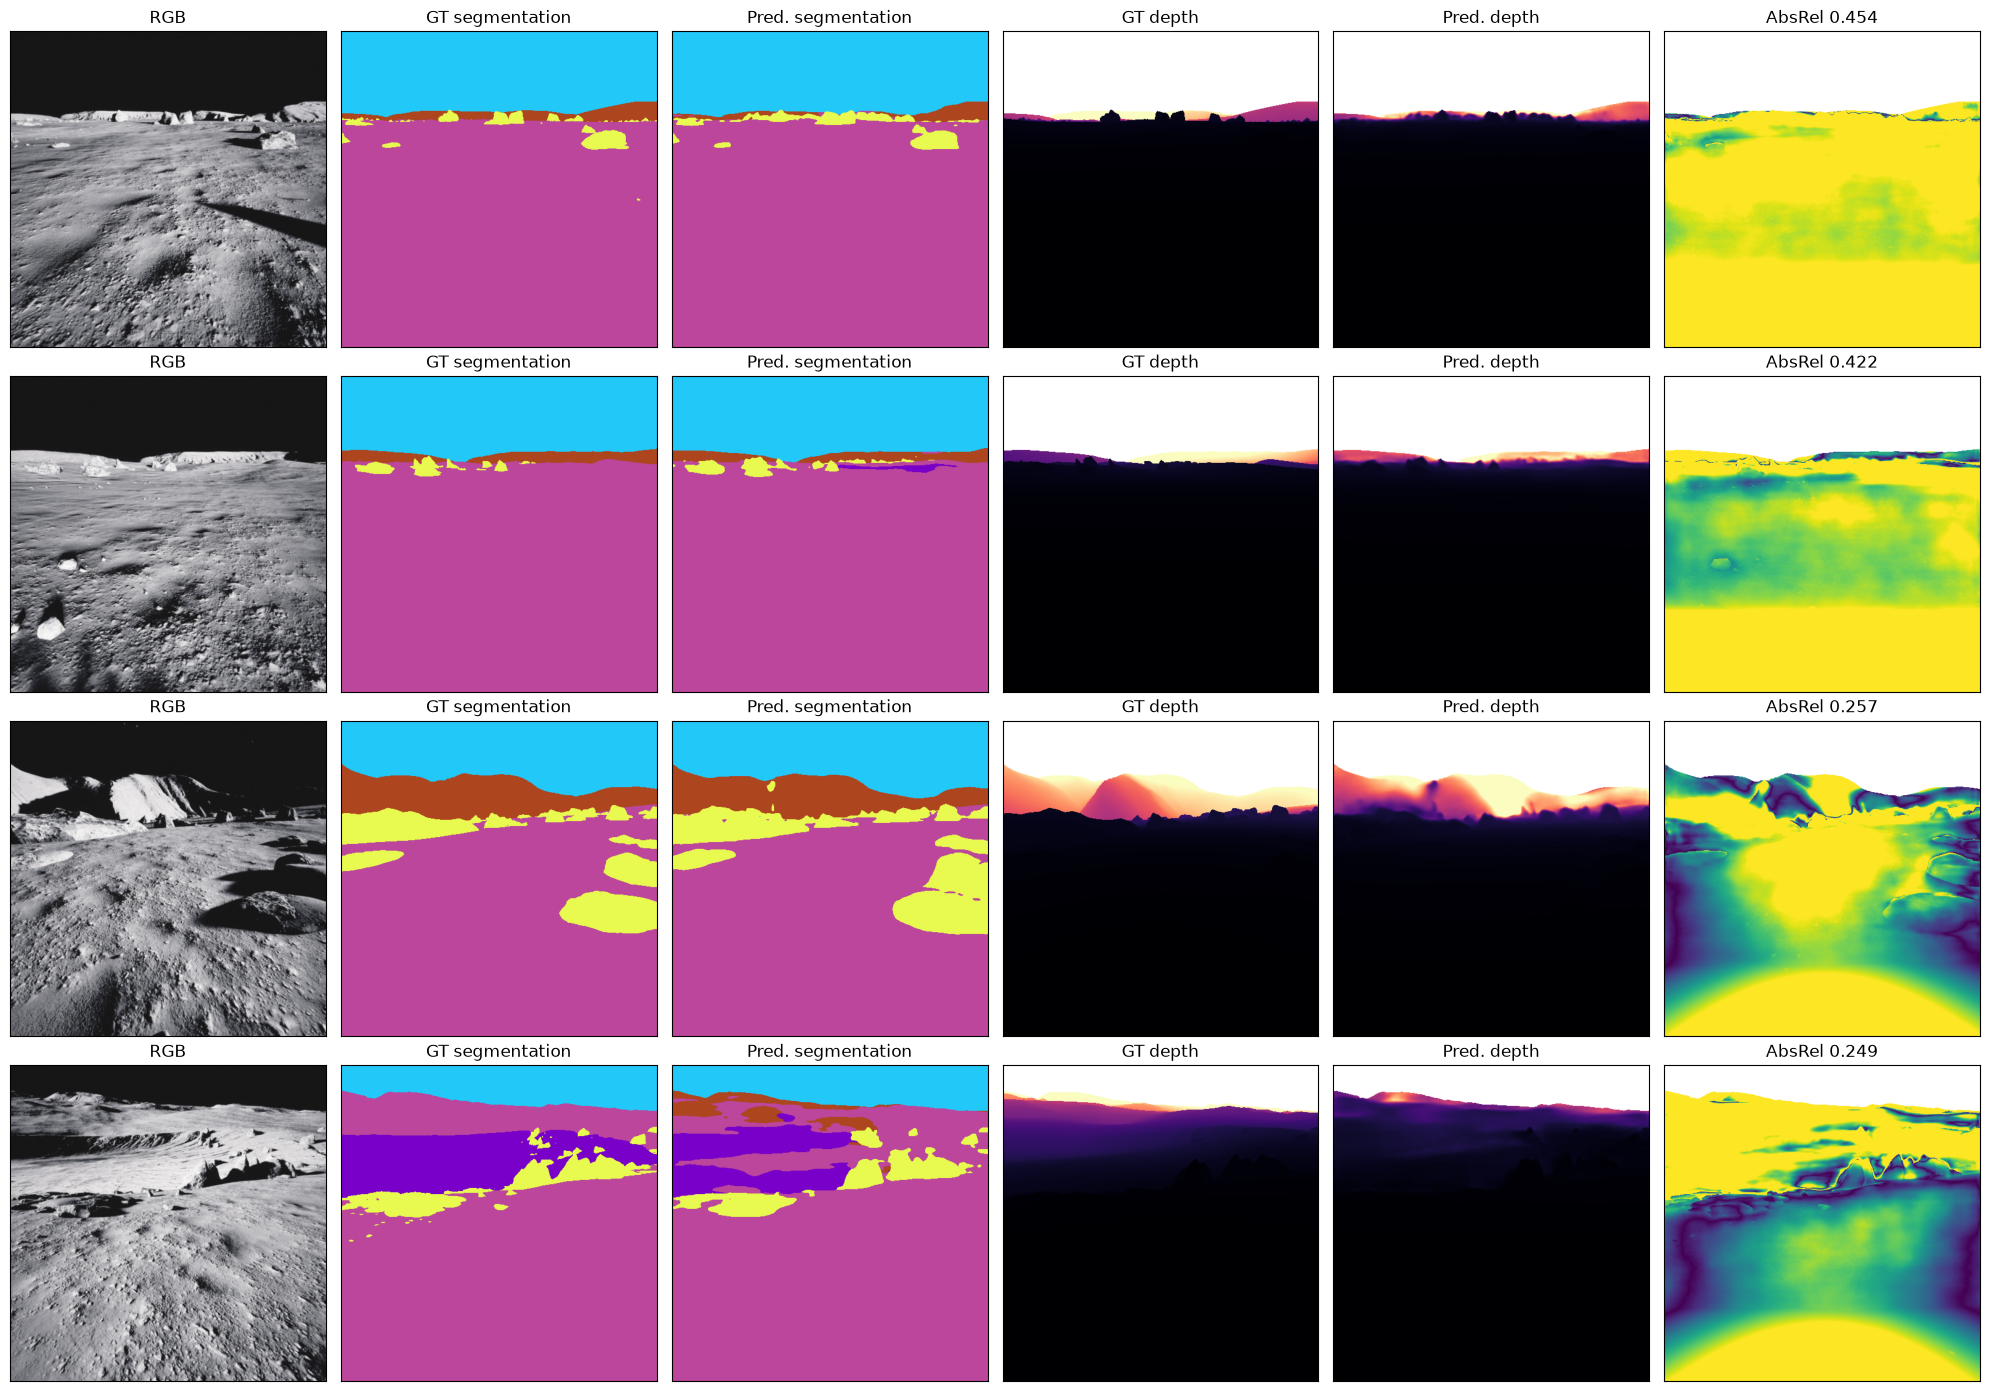

In [17]:
@torch.no_grad()
def plot_predictions(m, ds, n=4):
    ids=np.linspace(0,len(ds)-1,n).astype(int); samples=[ds[int(i)] for i in ids]
    x=torch.stack([s["image"] for s in samples]).to(DEVICE)
    with autocast(): o=m(x)
    seg=o["seg"].argmax(1).cpu().numpy(); depth=o["depth"].float().cpu().numpy()[:,0]
    fig,ax=plt.subplots(n,6,figsize=(20,3.5*n),squeeze=False)
    for i,s in enumerate(samples):
        valid=s["depth_valid"][0].numpy(); gt=s["depth"][0].numpy().copy(); gt[~valid]=np.nan
        pr=depth[i].copy(); pr[~valid]=np.nan; rel=np.abs(pr-gt)/gt; lo,hi=np.nanpercentile(gt,[1,99])
        ax[i,0].imshow(L.denormalize(s["image"]).permute(1,2,0).cpu().numpy()); ax[i,0].set_title("RGB")
        ax[i,1].imshow(L.class_to_rgb(s["label"].numpy())); ax[i,1].set_title("GT segmentation")
        ax[i,2].imshow(L.class_to_rgb(seg[i])); ax[i,2].set_title("Pred. segmentation")
        ax[i,3].imshow(gt,cmap="magma",vmin=lo,vmax=hi); ax[i,3].set_title("GT depth")
        ax[i,4].imshow(pr,cmap="magma",vmin=lo,vmax=hi); ax[i,4].set_title("Pred. depth")
        ax[i,5].imshow(rel,cmap="viridis",vmin=0,vmax=.3); ax[i,5].set_title(f"AbsRel {np.nanmean(rel):.3f}")
    for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); fig.savefig(RESULTS_DIR/"multitask_predictions.png",dpi=150); plt.show()

plot_predictions(model, datasets.get("test", datasets["val"]))